# Global CDR calculations
This script walks through how we scale up each region's representative run to calculate global CDR outcomes. 

There are a few different ways we can do it. All of them require the total amount of rock spread in each region to reach whatever GCAM simulated. This script assumes a fixed application rate and solves for the area required to reach the GCAM target. 

The representative run's application amount was constructed with the following rules:
1. Assume a fixed application flux for each region (in t/ha/yr) and solve for the area required to match the GCAM amount of rock for that region and year. 
2. If the cropland area required exceeds the total area available, increase the application flux accordingly (holding the area constant at 100%). 

## Postprocessing in a single region
Since more area can be added to the region's ERW over time, we need to start the new area from "square 1" (t=0). That way ERW that starts in 2040 doesn't implicitly carry pH buffering neutralization that's been ongoing since 2020. 

We do this by creating one new "deployment" every year (some deployments will spread no rock if total application doesn't increase). Each deployment follows the CDR trajectory of the region's representative run and is assigned an area equal to the change in regional area available for ERW. We ensure that the total amount of rock spread in the region each year aligns with the GCAM requirement. 

### Year = 0 calculation
We start with the year 0 condition, letting $j$ refer to year and $i$ to a deployment. Since we only have one deployment in year 0, we spread all of the rock GCAM prescribes to that region and year to a single deployment. Formally, 

$$M_\text{D, i} = M_\text{gcam, j}$$

when $i$ and $j$ equal zero. We can then calculate the total area required for the year 0 deployment ($A_\text{D, i}$; ha) because we know the application flux ($R_\text{j}$; t/ha/yr) in year 0 (and every year):

$$A_{D, 0} = \frac{M_\text{D, 0}}{R_0}.$$

Similarly, CDR for year 0 is just the CDR for that single deployment. 

### Year > 0 calculation
For each year after year 0, the new annual deployment depends on how much *new* rock is spread relative to what existing deployments are already going to do. For each deployment, $i$, we calculate the mass of rock spread in a year by: 

$$M_\text{D, i, j} = R_\text{j} \times A_\text{D, i}$$

Then, we get the amount of rock spread by existing deployments ($\mu_\text{j}$; t/yr) by summing them:

$$\mu_\text{j} = \sum_\text{i=0}^n M_\text{D, i, j}$$

Next, we can calculate how much new rock needs to be spread in year $j$ by comparing what existing deployments will do to what GCAM requires ($M_\text{GCAM, j}$; t/yr):

$$M_\text{new, j} = M_\text{GCAM, j} - \mu_\text{j}.$$

This new rock mass will be spread across the year's new deployment, at an area determined by the deployment's application flux that year. Since new deployments always start at $R_0$, we get:

$$A_\text{D, i} = \frac{M_\text{new, j}}{R_0}.$$

Deployment areas are generally fixed through time, with one exception. Since we rely on a single representative run to simulate many ERW deployments evolving over time, it's possible to reach a condition where $M_\text{new, j}$ is negative. That's because new deployments always start at $R_0$, but the representative rock spreading timeseries was calculating implicitly assuming new area kicks in at $R_j$, which can exceed $R_0$ in regions where there isn't enough cropland to hit $M_\text{GCAM, j}$ if $R_j=R_0$. The lower $R_0$ of the new deployment, compared to $R_j$, leads to a rock deficit that needs to be made up by excess area. When that deployment finally hits $R_j$ later on, it'll have "too much" area and we might see $M_\text{new, j}$ become negative. 

There's no clear physical meaning for a negative $M_\text{new, j}$. It's just a scaling quirk that we have to deal with that falls out of our decision to use a single representative run to capture the time-evolution of many emerging "deployments" through time. We expect that quirk to be pretty small, likely much smaller than the uncertainty associated with other model decisions like the specific surface area or CEC. Moreover, as long as GCAM deployments see rock amendments stabilizing for long enough after scale-up (and most do), deployment areas, too, will stabilize back so the total area equals the available cropland area. 

Since the more recent deployments are typically responsible for the area (and, later, mass) overshoot, we trim area off those first (first in, first out). If they need to be totally trimmed, then they are "turned off" completely. If $M_\text{new, j}$ becomes positive later, we start with a new deployment rather than turning a trimmed one back on or increasing its area. 

We could alternatively explore a last in, first out rule, or a "dormancy" rule where trimmed deployments can come back (picking up where they left off) when $M_\text{new, j}$ turns positive. Generally, we don't expect $M_\text{new, j}$ to become positive again after it first turns negative since all individual deployments see their $R$ staying the same or increasing monotonically. 

### Calculating CDR 
The area calculations are the tricky part. Once we have those, calculating CDR for a given region and year ($\text{CDR}_\text{j}$; t/yr) is simple. It's just the sum of every deployment's yearly CDR flux (t/ha/yr) multiplied by the deployment's area:

$$\text{CDR}_\text{j} = \sum_{i=0}^n \text{CDR}_\text{rate, i, j} \times A_\text{D, i}$$

### Variables
This postprocessing effort produces or uses the following variables, defined over the following coordinates: 
| VAR                   | COORDS                     | DESCRIPTION                    | UNITS          |
|-----------------------|----------------------------|--------------------------------|----------------|
| $R$                   | time, region, deployment   | application flux               | t/ha/yr        |
| $A_\text{D}$          | time, region, deployment   | deployment area                | ha             |
| $A_\text{total, ERW}$ | time, region               | total area for ERW             | ha             |
| $M_\text{GCAM}$       | time, region               | total rock spread              | t              |
| $M_\text{D}$          | time, region, deployment   | rock spread in deployment      | t              |
| $\mu$                 | time, region               | rock spread in old deployments | t              |
| $M_\text{new}$        | time, region               | rock spread in new deployment  | t              |
| $CDR_\text{flux}$     | time, region, deployment   | deployment-specific CDR        | t/ha/yr        |
| $CDR_\text{rate}$     | time, region               | region-specific CDR            | t/yr           |
| $A_\text{frac}$       | time, region               | total ERW area over total cropland area | ha    |


In [2]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import xarray as xr

import os

# ************************************************
# --- [ SCEPTER OUTPUTS ]
EXP_GROUP = "gcam_opr_psdfull_3axis1"
EXP_SET = 'exe_central1p5'
SAVE_GROUP = "gcam"
idx = "001"
#
# --- read in time-transient and integrated data
datpath = f"s3://carbonplan-carbon-removal/ew-workflows-data/scepter/postprocessed/{SAVE_GROUP}/{EXP_GROUP}/{EXP_SET}_{idx}"
fn_cdr = "ds_cdr.zarr"                  # time-integrated data
fn_cdr_trans = "ds_cdr_transient.zarr"  # time-transient data
# read in
ds = xr.open_zarr(os.path.join(datpath, fn_cdr))
ds_trans = xr.open_zarr(os.path.join(datpath, fn_cdr_trans))
# extract apprates for reading in rock flux data
apprates_arr = ds.apprate_base.values

# ************************************************
# --- [ ROCK FLUX INPUTS ]
RUN_FORMAT = 'one-cell-per-region'
DEG_RES = 1
rock_fn = f'annual_rockflx_densest-ag-region_{DEG_RES}deg.pkl'
dfrock_dict = {}
for apprate in apprates_arr:
    apprate_name = f'{apprate}-tHaYr-appRate'
    gcam_dir = f's3://carbonplan-carbon-removal/ew-workflows-data/gcam/apprate_calculated/{RUN_FORMAT}/{EXP_SET}/{apprate_name}'
    # [ read in ]
    dfrock_dict[apprate_name] = pd.read_pickle(os.path.join(gcam_dir, rock_fn))

# ************************************************
# --- [ CROPLAND MAP ]
# ( only used for crop areas so we just need one map )
ag_fn = f'cropland+gcamRegions_time_{DEG_RES}deg.zarr'
dsag_dict = {}
for apprate in apprates_arr:
    apprate_name = f'{apprate}-tHaYr-appRate'
    gcam_dir = f's3://carbonplan-carbon-removal/ew-workflows-data/gcam/apprate_calculated/{RUN_FORMAT}/{EXP_SET}/{apprate_name}'
    # [ read in ]
    dsag_dict[apprate_name] = xr.open_zarr(os.path.join(gcam_dir, ag_fn))


# TEST: Area + CDR calc for one region

In [ ]:
# --- select a single representative run 
this_region_idx   = 30
this_apprate_idx  = 0
this_dustrad_idx  = 2
this_cec_factor_idx = 1
ds_rep = ds_trans.isel(
    site=this_region_idx,
    apprate_base=this_apprate_idx,
    dustrad=this_dustrad_idx,
    cec_factor=this_cec_factor_idx,
).copy()
ds_rep['cdr_dif'].plot()

In [7]:
# Variables from ds_rep to carry through to every deployment
# varlist_deploy         : interpolated to the annual grid and stored as (time, deployment) lag matrices
# varlist_region         : subset of varlist_deploy → area-scaled regional total  (nansum(var * A_D))
# varist_region_cumfrac  : subset of varlist_deploy → cumulative rock-weighted regional mean (for feedstock fraction vars) 
varlist_deploy      = [    # e.g. ['total_dissolution', 'fraction_total_dissolved']
    'cdr_adv', 'cdr_dif', 'cdr_dif_component', 'cdr_resp_component', 'cdr_resp_component_noAE',
    'cdr_SIConly', 'co2pot_adv_tonHaYr_camg', 'co2pot_adv_tonHaYr_totcat', 'co2pot_tot_tonHaYr_camg',
    'co2pot_tot_tonHaYr_totcat', 'DICpot_adv_camg', 'DICpot_adv_totcat', 'fraction_remaining_dissolved',
    'fraction_sld_advected', 'fraction_sld_remaining', 'fraction_total_dissolved',
    'int_dust_ton_ha_yr', 'noncarbsld_source_ca', 'noncarbsld_source_mg', 'noncarbsld_source_k', 
    'noncarbsld_source_na', 'total_dissolution'
]   
varlist_region      = [      # e.g. ['total_dissolution']
    'cdr_adv', 'cdr_dif', 'cdr_dif_component', 'cdr_resp_component', 'cdr_resp_component_noAE',
    'cdr_SIConly', 'co2pot_adv_tonHaYr_camg', 'co2pot_adv_tonHaYr_totcat', 'co2pot_tot_tonHaYr_camg',
    'co2pot_tot_tonHaYr_totcat',
] 
varist_region_cumfrac = [   # e.g. ['fraction_total_dissolved']
    'fraction_remaining_dissolved',
    'fraction_sld_advected', 'fraction_sld_remaining', 'fraction_total_dissolved',
]   

## Step 1: Setup — time grid and base parameters
- set `t_start` to filter out the initial blip (usually pre 0.1 yr, so we choose 0.2 yr for safety margin)
- extract data arrays after `t_start` and reset time_0 to zero
- interpolate the timeseries to a regular, annual grid

Region     : Taiwan
R0         : 5.0 t/ha/yr
t_start    : 0.2 yr
Annual grid: 80 steps, years 0–79 (since t_start)
CDR flux   : 0.0718 → 3.1639 t/ha/yr


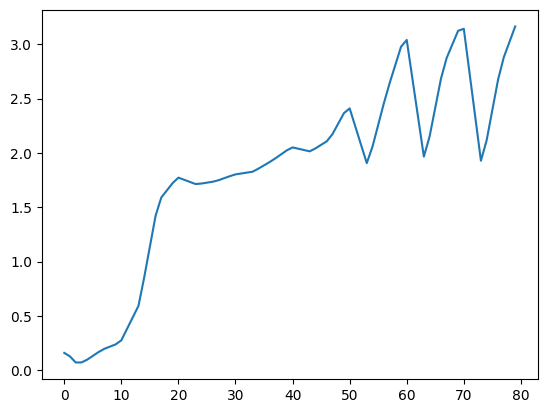

In [8]:
# raw SCEPTER data from the representative run
cdr_var     = 'cdr_adv'
time_raw    = ds_rep.time.values
cdr_raw     = ds_rep[cdr_var].values.copy()
R0          = float(ds.apprate_base.values[0])      # base application rate (t/ha/yr)
region_name = str(ds.site.values[this_region_idx])  # GCAM region label

# ---- skip the initial numerical blip ----
t_start = 0.2     # [yr] blip resolved by t ~= 0.1; we use 0.2 for safety margin

# ---- interpolate to a regular annual grid (years since t_start) ----
n_years   = int(time_raw[-1] - t_start)           # full years available after t_start
time_vals = np.arange(n_years + 1, dtype=float)   # [0, 1, ..., n_years]
cdr_vals  = np.interp(time_vals + t_start, time_raw, cdr_raw)
n_time    = len(time_vals)

# ---- interpolate varlist_deploy variables to the same annual grid ----
extra_vals = {
    vname: np.interp(time_vals + t_start, time_raw, ds_rep[vname].values.copy())
    for vname in varlist_deploy
}

print(f"Region     : {region_name}")
print(f"R0         : {R0} t/ha/yr")
print(f"t_start    : {t_start} yr")
print(f"Annual grid: {n_time} steps, years 0–{n_years} (since t_start)")
print(f"CDR flux   : {cdr_vals.min():.4f} → {cdr_vals.max():.4f} t/ha/yr")

plt.plot(time_vals, cdr_vals)

## Step 2: Build CDR\_flux(time, deployment)

This is a lower-triangular lag matrix. Deployment $ starts at time step $ and follows
the representative run from the beginning. At time step  \geq i$ it has "age" $,
so its CDR flux is .

In [9]:
deploy_coords = np.arange(n_time)

# Uniform annual grid --> deployment i at time step j has elapsed exactly (j − i) years.
# CDR_flux_2d[j, i] = cdr_vals[j − i]  for j >= i, else NaN
CDR_flux_2d = np.full((n_time, n_time), np.nan)  # `deployment` dim has same length as `n_time`
for i in range(n_time):
    CDR_flux_2d[i:, i] = cdr_vals[:n_time - i]

CDR_flux = xr.DataArray(
    CDR_flux_2d,
    coords={'time': time_vals, 'deployment': deploy_coords},
    dims=['time', 'deployment'],
    name='CDR_flux',
    attrs={'units': 't/ha/yr', 'description': 'CDR flux per unit area for each deployment'}
)

# ---- build lag matrices for each variable in varlist_deploy ----
extra_flux_2d = {}
for vname, vals in extra_vals.items():
    mat = np.full((n_time, n_time), np.nan)
    for i in range(n_time):
        mat[i:, i] = vals[:n_time - i]
    extra_flux_2d[vname] = mat

# print(CDR_flux)
print(f"Col 0 matches cdr_vals: {np.allclose(CDR_flux_2d[:, 0], cdr_vals)}")
print(f"Row 0 non-NaN: {np.sum(~np.isnan(CDR_flux_2d[0, :]))} (expect 1)")

Col 0 matches cdr_vals: True
Row 0 non-NaN: 1 (expect 1)


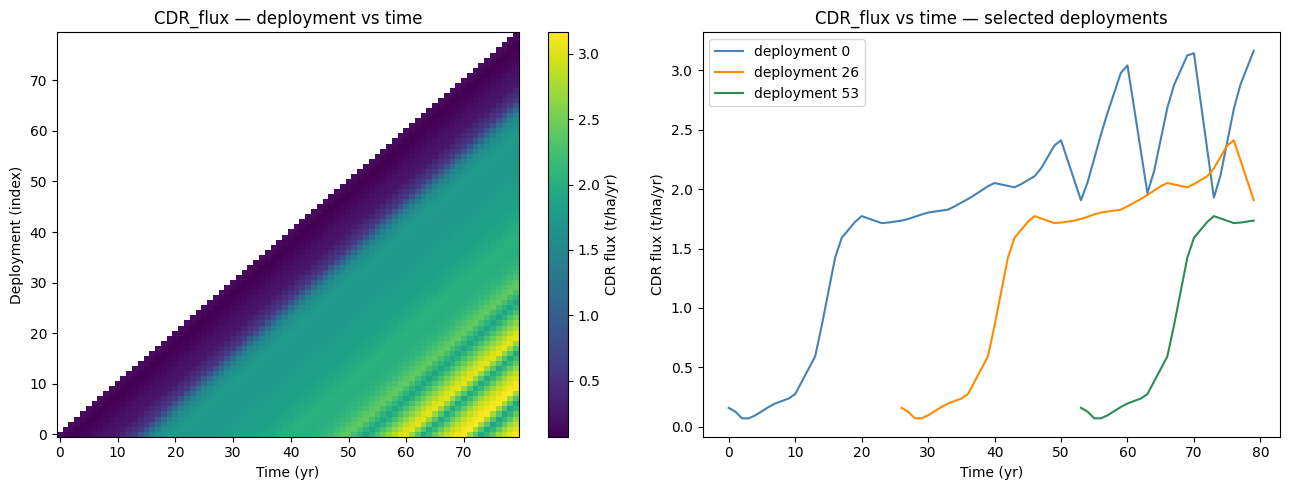

In [10]:
# --- Quick visual check of CDR_flux(time, deployment) ---
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Left: 2D heatmap — deployment vs time, colored by CDR_flux
im = axes[0].pcolormesh(
    time_vals, deploy_coords, CDR_flux_2d.T,
    cmap='viridis', shading='auto'
)
fig.colorbar(im, ax=axes[0], label='CDR flux (t/ha/yr)')
axes[0].set_xlabel('Time (yr)')
axes[0].set_ylabel('Deployment (index)')
axes[0].set_title('CDR_flux — deployment vs time')

# Right: CDR_flux vs time for 3 representative deployments
n_dep = n_time
sample_deps = [0, n_dep // 3, 2 * n_dep // 3]
colors = ['steelblue', 'darkorange', 'seagreen']
for dep_i, color in zip(sample_deps, colors):
    flux_i = CDR_flux_2d[:, dep_i]
    axes[1].plot(time_vals, flux_i, color=color, label=f'deployment {dep_i}')
axes[1].set_xlabel('Time (yr)')
axes[1].set_ylabel('CDR flux (t/ha/yr)')
axes[1].set_title('CDR_flux vs time — selected deployments')
axes[1].legend()

plt.tight_layout()

## Step 3: Build R\_flux(time, deployment) and initialize dataset

Extract the effective rock application rate (`effective_rate_t_ha`, t/ha/yr) from the GCAM df for this region and apprate, then build the same lower-triangular lag matrix as `CDR_flux`. `R_flux_2d[j, i]` is the per-ha rock application rate for deployment $i$ at time step $j$, i.e. `r_vals[j − i]`. Using `effective_rate_t_ha` (rather than the constant `R0`) captures the time-varying rate that results when the cropland-area constraint becomes binding.

Note, `effective_rate_t_ha` is identical to `rockflx_t_ha_yr`. Timesteps are one per year. 

In [11]:
# --- filter GCAM df to this region + apprate ---
apprate_key = f'{float(apprates_arr[this_apprate_idx])}-tHaYr-appRate'   # matches ds_rep (apprate_base=0)
df_rock     = dfrock_dict[apprate_key]
df_region   = (df_rock[df_rock['reg_id'] == this_region_idx]
               .sort_values('time').reset_index(drop=True))

gcam_t0    = int(df_region['time'].min())
gcam_years = df_region['time'].values.astype(float)

# Rock application rate timeseries — effective_rate_t_ha accounts for the area constraint
r_gcam  = df_region['effective_rate_t_ha'].values
r_vals  = np.interp(time_vals, gcam_years - gcam_t0, r_gcam,
                    left=r_gcam[0], right=r_gcam[-1])

# Build R_flux lag matrix (same lower-triangular structure as CDR_flux_2d)
# R_flux_2d[j, i] = r_vals[j - i]  for j >= i, else NaN
R_flux_2d = np.full((n_time, n_time), np.nan)
for i in range(n_time):
    R_flux_2d[i:, i] = r_vals[:n_time - i]

R_flux = xr.DataArray(
    R_flux_2d,
    coords={'time': time_vals, 'deployment': deploy_coords},
    dims=['time', 'deployment'],
    name='R_flux',
    attrs={'units': 't/ha/yr', 'description': 'Rock application rate per deployment'}
)

print(f"R range: {r_vals.min():.3f} – {r_vals.max():.3f} t/ha/yr  (R0 = {R0:.3f})")

# Build deployment-level DataArrays for varlist_deploy variables
extra_deploy_da = {
    f'{vname}_deployment': xr.DataArray(
        extra_flux_2d[vname],
        coords={'time': time_vals, 'deployment': deploy_coords},
        dims=['time', 'deployment'],
        name=f'{vname}_deployment',
        attrs={
            'units': str(ds_rep[vname].attrs.get('units', '')),
            'description': f'{vname} per unit area for each deployment'
        }
    )
    for vname in varlist_deploy
}

# Initialize dataset — remaining variables added in Step 7
ds_out = xr.Dataset({
    f'{cdr_var}_deployment': CDR_flux,
    'rockflx_t_ha_yr': R_flux,
    **extra_deploy_da,
})
ds_out.attrs['region'] = region_name
ds_out

R range: 5.000 – 16.695 t/ha/yr  (R0 = 5.000)


<xarray.Dataset> Size: 1MB
Dimensions:                                  (time: 80, deployment: 80)
Coordinates:
  * time                                     (time) float64 640B 0.0 ... 79.0
  * deployment                               (deployment) int64 640B 0 1 ... 79
Data variables: (12/23)
    cdr_adv_deployment                       (time, deployment) float64 51kB ...
    rockflx_t_ha_yr                          (time, deployment) float64 51kB ...
    cdr_dif_deployment                       (time, deployment) float64 51kB ...
    cdr_dif_component_deployment             (time, deployment) float64 51kB ...
    cdr_resp_component_deployment            (time, deployment) float64 51kB ...
    cdr_resp_component_noAE_deployment       (time, deployment) float64 51kB ...
    ...                                       ...
    int_dust_ton_ha_yr_deployment            (time, deployment) float64 51kB ...
    noncarbsld_source_ca_deployment          (time, deployment) float64 51kB ...
    noncarbsld_source_mg_deployment          (time, deployment) float64 51kB ...
    noncarbsld_source_k_deployment           (time, deployment) float64 51kB ...
    noncarbsld_source_na_deployment          (time, deployment) float64 51kB ...
    total_dissolution_deployment             (time, deployment) float64 51kB ...
Attributes:
    region:   Taiwan

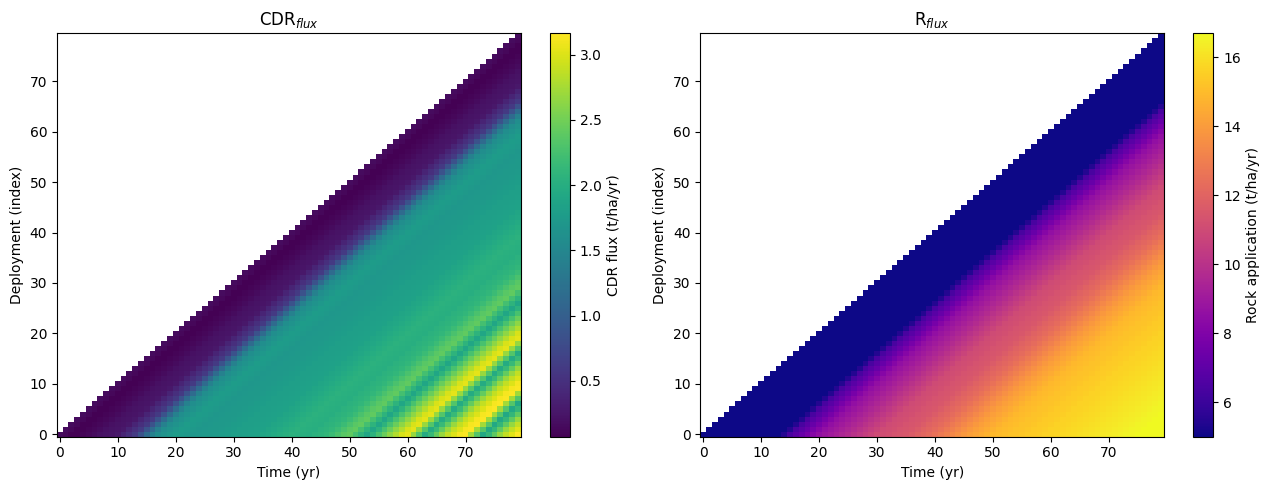

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

for ax, data, label, cmap in [
    (axes[0], CDR_flux_2d,  'CDR flux (t/ha/yr)',          'viridis'),
    (axes[1], R_flux_2d,    'Rock application (t/ha/yr)',   'plasma'),
]:
    im = ax.pcolormesh(time_vals, deploy_coords, data.T, cmap=cmap, shading='auto')
    fig.colorbar(im, ax=ax, label=label)
    ax.set_xlabel('Time (yr)')
    ax.set_ylabel('Deployment (index)')

axes[0].set_title(r'CDR$_{flux}$')
axes[1].set_title(r'R$_{flux}$')
plt.tight_layout()

## Step 4: Define M\_GCAM

Recover total annual rock mass (t/yr) for this region from `gcam_gross_cdr_mtCO2` using the same
conversion as in `calculate-rock-fluxes-from-GCAM.ipynb`:
`rockflx_Mt_yr = gcam_gross_cdr_mtCO2 / basalt_cdrpot`, so `rockflx_t_yr = gcam_gross_cdr_mtCO2 / basalt_cdrpot * 1e6`.

`df_region`, `gcam_t0`, and `gcam_years` are already defined in Step 3.

M_GCAM range: 0.000e+00 – 8.617e+06 t/yr


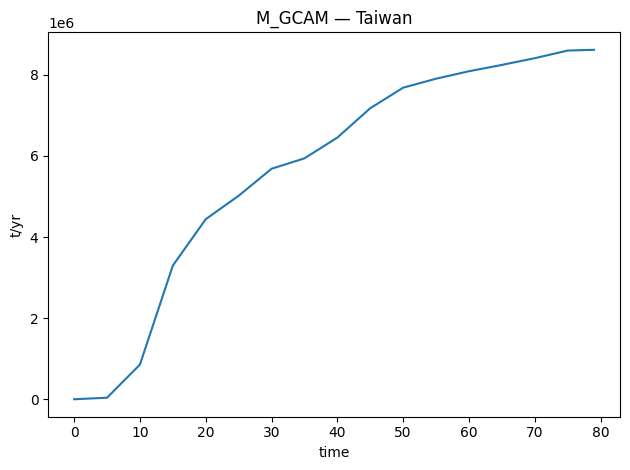

In [13]:
# df_region, gcam_t0, gcam_years defined in Step 3
basalt_cdrpot = 0.3   # [g CO2 / g basalt]
gcam_rock_t = df_region['gcam_gross_cdr_mtCO2'].values / basalt_cdrpot * 1e6   # MtCO2/yr --> t rock/yr
m_gcam_vals = np.interp(time_vals, gcam_years - gcam_t0, gcam_rock_t,
                        left=0.0, right=gcam_rock_t[-1])

M_GCAM = xr.DataArray(
    m_gcam_vals,
    coords={'time': time_vals},
    dims=['time'],
    name='M_GCAM',
    attrs={'units': 't/yr', 'description': f'Annual rock mass target from GCAM ({region_name})'}
)

print(f"M_GCAM range: {m_gcam_vals.min():.3e} – {m_gcam_vals.max():.3e} t/yr")

plt.figure()
M_GCAM.plot()
plt.title(f'M_GCAM — {region_name}')
plt.ylabel('t/yr')
plt.tight_layout()

## Step 5: Iterative area calculation

For each time step $j$:
1. Carry forward deployment areas from $j-1$.
2. Compute $\mu_j = \sum_{i<j} R_\text{flux}[j,i] \cdot A_{D,i,j}$ using the time-varying rate from `R_flux_2d` (not the constant `R0`).
3. $M_\text{new,j} = M_\text{GCAM,j} - \mu_j$.
4. If $\geq 0$: open deployment $j$ with area $M_\text{new,j} / r_\text{vals}[0]$ (new deployments always start at elapsed $t=0$, so $R = r_\text{vals}[0] = R_0$).
5. If $< 0$: trim the most-recent active deployments (newest-first), adjusting area as $\Delta A = \text{excess} / R_\text{flux}[j, i]$.

In [14]:
R_flux_2d = ds_out['rockflx_t_ha_yr'].values   # pull from ds_out to avoid stale references

A_D_2d    = np.full((n_time, n_time), np.nan)
M_D_2d    = np.full((n_time, n_time), np.nan)
mu_arr    = np.zeros(n_time)
M_new_arr = np.zeros(n_time)

for j in range(n_time):
    if j > 0:
        A_D_2d[j, :] = A_D_2d[j-1, :]   # carry forward (NaN propagates for not-yet-open)

    # Rock from already-open deployments using their time-varying application rate
    M_D_2d[j, :j]  = R_flux_2d[j, :j] * A_D_2d[j, :j]
    mu_arr[j]       = np.nansum(M_D_2d[j, :j])

    M_new_arr[j] = float(M_GCAM.values[j]) - mu_arr[j]

    if M_new_arr[j] >= 0:
        # New deployments always start at elapsed t=0, so R = r_vals[0] = R0
        A_D_2d[j, j] = M_new_arr[j] / r_vals[0]
        M_D_2d[j, j] = M_new_arr[j]
    else:
        # Trim newest deployments first; area reduction uses the deployment's current R.
        # Use `not (x > 0)` rather than `x <= 0` so NaN-area deployments (years where
        # M_new was also negative and no deployment was opened) are correctly skipped.
        excess = -M_new_arr[j]
        for i_trim in range(j - 1, -1, -1):
            if not (A_D_2d[j, i_trim] > 0):   # skips NaN and zero/negative areas
                continue
            removable = M_D_2d[j, i_trim]
            if removable <= excess:
                A_D_2d[j, i_trim] = 0.0
                M_D_2d[j, i_trim] = 0.0
                excess -= removable
            else:
                A_D_2d[j, i_trim] -= excess / R_flux_2d[j, i_trim]
                M_D_2d[j, i_trim] -= excess
                excess = 0.0
            if excess <= 0:
                break

total_rock = np.nansum(M_D_2d, axis=1)
print(f"Max |total_rock - M_GCAM| = {np.abs(total_rock - M_GCAM.values).max():.2e} t/yr")

Max |total_rock - M_GCAM| = 1.86e-09 t/yr


## Step 6: CDR rate = sum of (CDR flux × area) across deployments

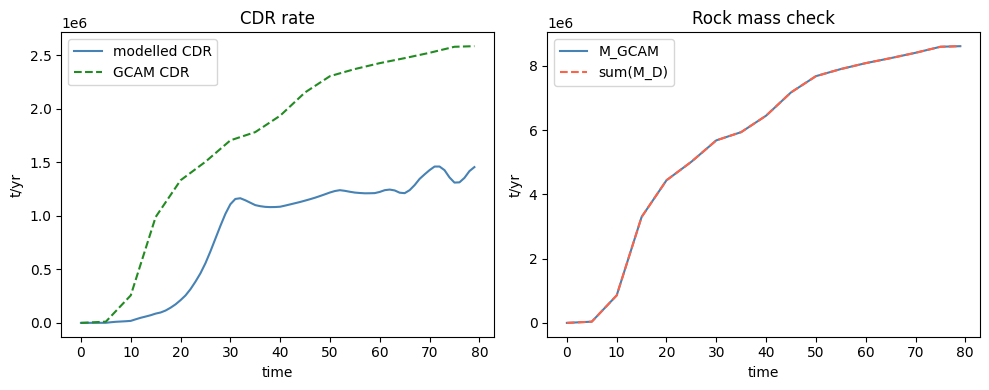

In [15]:
# CDR_rate[j] = sum_i( CDR_flux[j, i] * A_D[j, i] )  — NaN * NaN treated as 0
CDR_rate_vals = np.nansum(ds_out[f'{cdr_var}_deployment'].values * A_D_2d, axis=1)

CDR_rate = xr.DataArray(
    CDR_rate_vals,
    coords={'time': time_vals},
    dims=['time'],
    name=f'{cdr_var}_region',
    attrs={'units': 't/yr', 'description': 'Total CDR for the region'}
)

# GCAM-derived regional CDR interpolated onto time_vals (gcam_years, gcam_t0 from Step 3)
gcam_cdr_t    = df_region['gcam_gross_cdr_mtCO2'].values * 1e6   # MtCO2/yr → tCO2/yr
gcam_cdr_vals = np.interp(time_vals, gcam_years - gcam_t0, gcam_cdr_t,
                           left=0.0, right=gcam_cdr_t[-1])

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
CDR_rate.plot(ax=axes[0], label='modelled CDR', color='steelblue')
axes[0].plot(time_vals, gcam_cdr_vals, label='GCAM CDR', color='forestgreen', ls='--')
axes[0].set_title('CDR rate')
axes[0].set_ylabel('t/yr')
axes[0].legend()
M_GCAM.plot(ax=axes[1], label='M_GCAM', color='steelblue')
pd.Series(total_rock, index=time_vals).plot(ax=axes[1], label='sum(M_D)', ls='--', color='tomato')
axes[1].set_title('Rock mass check')
axes[1].set_ylabel('t/yr')
axes[1].legend()
plt.tight_layout()

## Step 7: Assemble xarray Dataset

`ds_out` was initialized in Step 3 with `CDR_flux` and `R_flux`. Add the remaining variables here.

In [16]:
coords_td = {'time': time_vals, 'deployment': deploy_coords}
coords_t  = {'time': time_vals}

# total cropland ha for this region — pick any pixel in the region; cropland_area_by_region
# stores the regional total repeated across all pixels, so one cell is sufficient
dsag = dsag_dict[apprate_key]
mask = (dsag['reg_id'].values == this_region_idx)
total_cropland_ha = float(dsag['cropland_area_by_region'].values[mask][0]) / 1e4

# --- Pass 1: add arrays computed in Step 5 ---
ds_out = ds_out.assign({
    'A_D'   : xr.DataArray(A_D_2d,   coords=coords_td, dims=['time', 'deployment'],
                            attrs={'units': 'ha',   'description': 'Deployment area (NaN = not yet open)'}),
    'M_D'   : xr.DataArray(M_D_2d,   coords=coords_td, dims=['time', 'deployment'],
                            attrs={'units': 't/yr', 'description': 'Rock mass per deployment (NaN = not yet open)'}),
    'M_GCAM': M_GCAM,
    'mu'    : xr.DataArray(mu_arr,    coords=coords_t,  dims=['time'],
                            attrs={'units': 't/yr', 'description': 'Rock from existing deployments'}),
    'M_new' : xr.DataArray(M_new_arr, coords=coords_t,  dims=['time'],
                            attrs={'units': 't/yr', 'description': 'Rock allocated to new deployment'}),
})

# --- Pass 2: derive summary variables from ds_out ---
A_total_ERW_vals = np.nansum(ds_out['A_D'].values, axis=1)

# cumulative rock applied per deployment up to each time step — weight for varist_region_cumfrac
# nancumsum treats NaN (not-yet-open) as 0, so pre-deployment years contribute nothing
cumM_D_2d     = np.nancumsum(ds_out['M_D'].values, axis=0)
cumM_D_total  = np.nansum(cumM_D_2d, axis=1)   # denominator: total cumulative rock in region

ds_out = ds_out.assign({
    'A_total_ERW': xr.DataArray(
        A_total_ERW_vals, coords=coords_t, dims=['time'],
        attrs={'units': 'ha', 'description': 'Total ERW area'}
    ),
    f'{cdr_var}_region': xr.DataArray(
        np.nansum(ds_out[f'{cdr_var}_deployment'].values * ds_out['A_D'].values, axis=1),
        coords=coords_t, dims=['time'],
        attrs={'units': 't/yr', 'description': 'Total CDR for the region'}
    ),
    'gcam_cdr': xr.DataArray(
        gcam_cdr_vals, coords=coords_t, dims=['time'],
        attrs={'units': 'tCO2/yr', 'description': 'GCAM-derived regional CDR'}
    ),
    # varlist_region: area-scaled regional totals
    **{
        f'{vname}_region': xr.DataArray(
            np.nansum(ds_out[f'{vname}_deployment'].values * A_D_2d, axis=1),
            coords=coords_t, dims=['time'],
            attrs={
                'units': 't/yr',
                'description': f'Area-scaled regional total for {vname}'
            }
        )
        for vname in varlist_region
    },
    # varist_region_cumfrac: cumulative-rock-mass-weighted mean for time-integrated fraction vars.
    # Each deployment is weighted by its cumulative applied rock, so the result answers:
    # "of all rock ever spread in this region, what fraction has dissolved by year j?"
    # NaN where no rock has been applied yet.
    **{
        f'{vname}_region': xr.DataArray(
            np.nansum(ds_out[f'{vname}_deployment'].values * cumM_D_2d, axis=1) / cumM_D_total,
            coords=coords_t, dims=['time'],
            attrs={
                'units': str(ds_rep[vname].attrs.get('units', '')),
                'description': f'Cumulative-rock-weighted regional mean for {vname}'
            }
        )
        for vname in varist_region_cumfrac
    },
})

# --- Pass 3: variables that depend on A_total_ERW ---
ds_out = ds_out.assign({
    'cropland_ha_total': xr.DataArray(
        total_cropland_ha,
        attrs={'units': 'ha', 'description': 'Total cropland area in the region (time-invariant)'}
    ),
    'cropfrac_ERW': xr.DataArray(
        ds_out['A_total_ERW'].values / total_cropland_ha, coords=coords_t, dims=['time'],
        attrs={'units': '-', 'description': 'Fraction of regional cropland under ERW'}
    ),
})

ds_out

/var/folders/2r/w7zcr7vx4p5cr7n4d0b51f4c0000gn/T/ipykernel_87695/2598797599.py:63: RuntimeWarning: invalid value encountered in divide
  np.nansum(ds_out[f'{vname}_deployment'].values * cumM_D_2d, axis=1) / cumM_D_total,


<xarray.Dataset> Size: 1MB
Dimensions:                                  (time: 80, deployment: 80)
Coordinates:
  * time                                     (time) float64 640B 0.0 ... 79.0
  * deployment                               (deployment) int64 640B 0 1 ... 79
Data variables: (12/46)
    cdr_adv_deployment                       (time, deployment) float64 51kB ...
    rockflx_t_ha_yr                          (time, deployment) float64 51kB ...
    cdr_dif_deployment                       (time, deployment) float64 51kB ...
    cdr_dif_component_deployment             (time, deployment) float64 51kB ...
    cdr_resp_component_deployment            (time, deployment) float64 51kB ...
    cdr_resp_component_noAE_deployment       (time, deployment) float64 51kB ...
    ...                                       ...
    fraction_remaining_dissolved_region      (time) float64 640B nan ... 0.9694
    fraction_sld_advected_region             (time) float64 640B nan ... 0.0651
    fraction_sld_remaining_region            (time) float64 640B nan ... 0.02857
    fraction_total_dissolved_region          (time) float64 640B nan ... 0.9063
    cropland_ha_total                        float64 8B 5.162e+05
    cropfrac_ERW                             (time) float64 640B 0.0 ... 1.032
Attributes:
    region:   Taiwan

# Explore results

## Visual checks

Four panels covering the key quantities in `ds_out`:
1. **Rock mass balance** — does `sum(M_D)` track `M_GCAM`? Where does `M_new` go negative?
2. **Area evolution** — how does `A_total_ERW` compare to the cropland ceiling?
3. **CDR outcomes** — modelled CDR vs the GCAM target
4. **Deployment heatmaps** — how area and rock mass are distributed across deployments over time

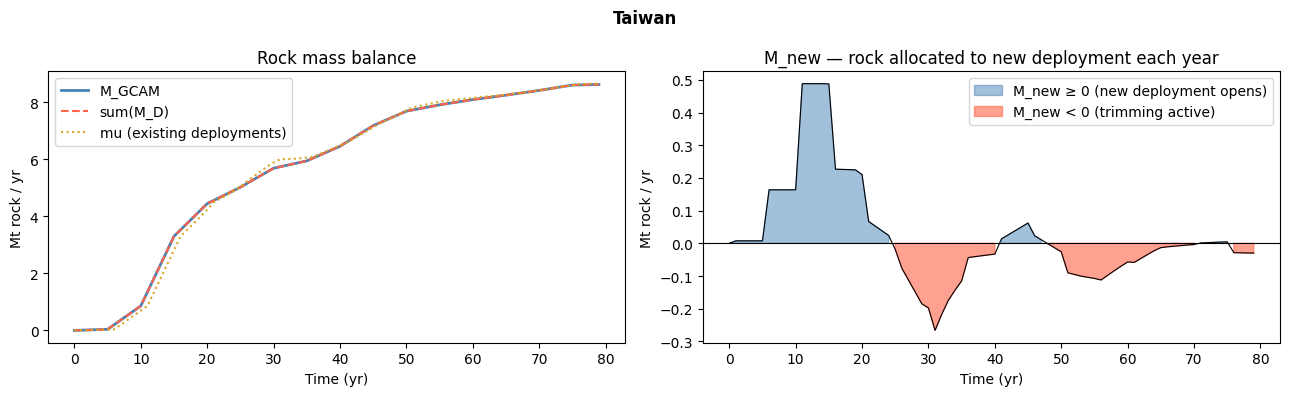

In [17]:
# --- 1. Rock mass balance + M_new ---
# all inputs come from ds_out
import matplotlib.pyplot as plt
import numpy as np

_t        = ds_out.time.values
_deps     = ds_out.deployment.values
_region   = ds_out.attrs['region']
_M_GCAM   = ds_out['M_GCAM'].values
_mu       = ds_out['mu'].values
_M_new    = ds_out['M_new'].values
_total_rock = np.nansum(ds_out['M_D'].values, axis=1)

fig, axes = plt.subplots(1, 2, figsize=(13, 4))

axes[0].plot(_t, _M_GCAM / 1e6,      label='M_GCAM',                  color='steelblue',  lw=2)
axes[0].plot(_t, _total_rock / 1e6,  label='sum(M_D)',                 color='tomato',     ls='--', lw=1.5)
axes[0].plot(_t, _mu / 1e6,          label='mu (existing deployments)', color='goldenrod',  ls=':',  lw=1.5)
axes[0].set_xlabel('Time (yr)')
axes[0].set_ylabel('Mt rock / yr')
axes[0].set_title('Rock mass balance')
axes[0].legend()

_m_new_Mt = _M_new / 1e6
axes[1].axhline(0, color='k', lw=0.8)
axes[1].fill_between(_t, _m_new_Mt, 0, where=(_m_new_Mt >= 0),
                     color='steelblue', alpha=0.5, label='M_new ≥ 0 (new deployment opens)')
axes[1].fill_between(_t, _m_new_Mt, 0, where=(_m_new_Mt < 0),
                     color='tomato',    alpha=0.6, label='M_new < 0 (trimming active)')
axes[1].plot(_t, _m_new_Mt, color='k', lw=0.8)
axes[1].set_xlabel('Time (yr)')
axes[1].set_ylabel('Mt rock / yr')
axes[1].set_title('M_new — rock allocated to new deployment each year')
axes[1].legend()

plt.suptitle(_region, fontweight='bold')
plt.tight_layout()

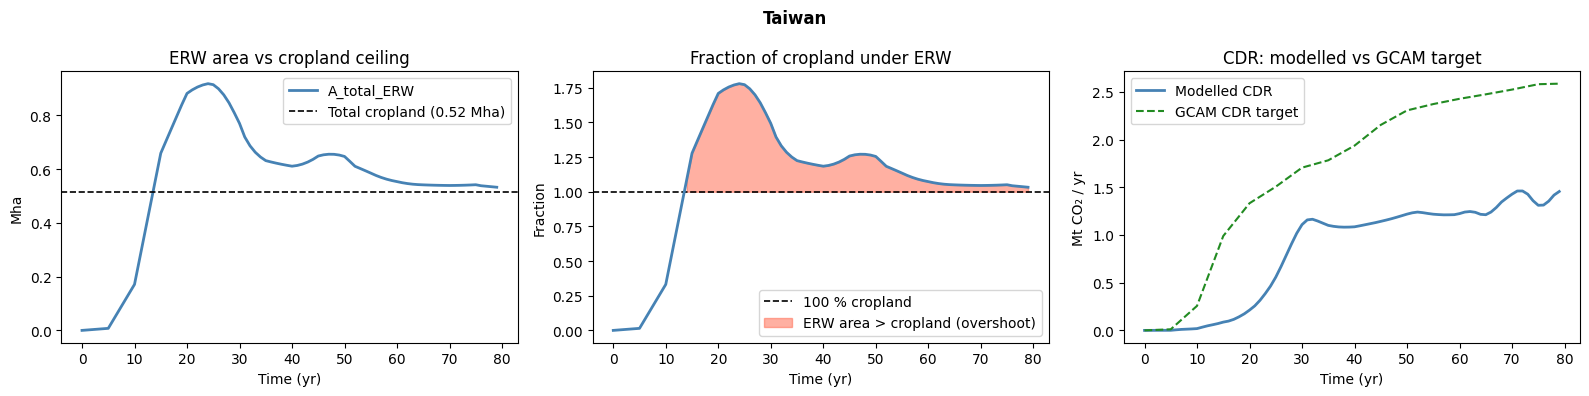

In [18]:
# --- 2. Area evolution + CDR outcomes ---
import matplotlib.pyplot as plt
import numpy as np

_t           = ds_out.time.values
_region      = ds_out.attrs['region']
_A_ERW       = ds_out['A_total_ERW'].values
_cropland_ha = float(ds_out['cropland_ha_total'].values)
_cropfrac    = ds_out['cropfrac_ERW'].values
_cdr_mod     = ds_out[f'{cdr_var}_region'].values
_cdr_gcam    = ds_out['gcam_cdr'].values

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].plot(_t, _A_ERW / 1e6, color='steelblue', lw=2, label='A_total_ERW')
axes[0].axhline(_cropland_ha / 1e6, color='k', ls='--', lw=1.2,
                label=f'Total cropland ({_cropland_ha/1e6:.2f} Mha)')
axes[0].set_xlabel('Time (yr)')
axes[0].set_ylabel('Mha')
axes[0].set_title('ERW area vs cropland ceiling')
axes[0].legend()

axes[1].axhline(1.0, color='k', ls='--', lw=1.2, label='100 % cropland')
axes[1].fill_between(_t, _cropfrac, 1, where=(_cropfrac > 1),
                     color='tomato', alpha=0.5, label='ERW area > cropland (overshoot)')
axes[1].plot(_t, _cropfrac, color='steelblue', lw=2)
axes[1].set_xlabel('Time (yr)')
axes[1].set_ylabel('Fraction')
axes[1].set_title('Fraction of cropland under ERW')
axes[1].legend()

axes[2].plot(_t, _cdr_mod  / 1e6, color='steelblue',   lw=2,   label='Modelled CDR')
axes[2].plot(_t, _cdr_gcam / 1e6, color='forestgreen',  ls='--', lw=1.5, label='GCAM CDR target')
axes[2].set_xlabel('Time (yr)')
axes[2].set_ylabel('Mt CO₂ / yr')
axes[2].set_title('CDR: modelled vs GCAM target')
axes[2].legend()

plt.suptitle(_region, fontweight='bold')
plt.tight_layout()

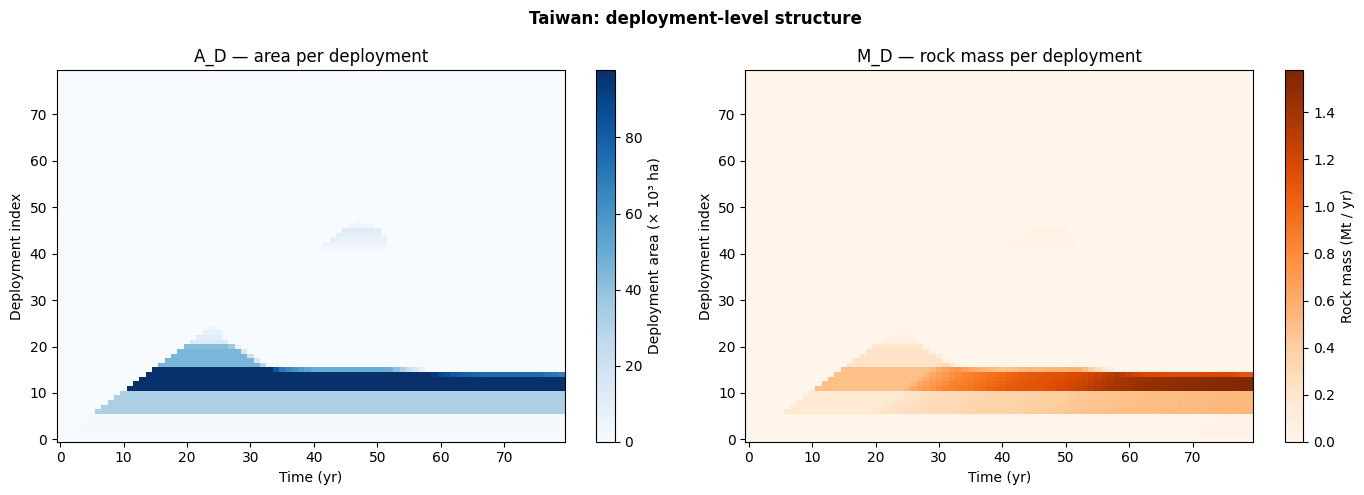

In [19]:
# --- 3. Deployment-level heatmaps: A_D and M_D ---
import matplotlib.pyplot as plt
import numpy as np

_t      = ds_out.time.values
_deps   = ds_out.deployment.values
_region = ds_out.attrs['region']
_A_D    = np.where(np.isnan(ds_out['A_D'].values), 0, ds_out['A_D'].values)
_M_D    = np.where(np.isnan(ds_out['M_D'].values), 0, ds_out['M_D'].values)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, data, label, cmap in [
    (axes[0], _A_D / 1e3, 'Deployment area (× 10³ ha)', 'Blues'),
    (axes[1], _M_D / 1e6, 'Rock mass (Mt / yr)',         'Oranges'),
]:
    im = ax.pcolormesh(_t, _deps, data.T, cmap=cmap, shading='auto')
    fig.colorbar(im, ax=ax, label=label)
    ax.set_xlabel('Time (yr)')
    ax.set_ylabel('Deployment index')

axes[0].set_title('A_D — area per deployment')
axes[1].set_title('M_D — rock mass per deployment')

plt.suptitle(f'{_region}: deployment-level structure', fontweight='bold')
plt.tight_layout()

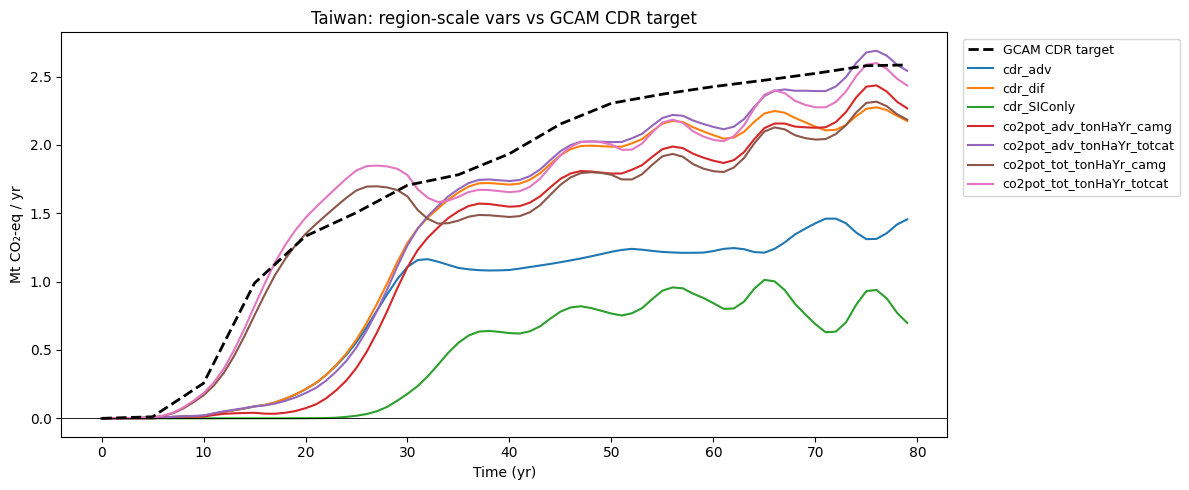

In [21]:
# --- 4. All _region vars vs GCAM CDR ---
import matplotlib.pyplot as plt
import numpy as np

_t      = ds_out.time.values
_region = ds_out.attrs['region']

region_keys = [f'{v}_region' for v in varlist_region if f'{v}_region' in ds_out and '_component' not in v]

fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(_t, ds_out['gcam_cdr'].values / 1e6,
        color='k', ls='--', lw=2, label='GCAM CDR target', zorder=10)

colors = plt.cm.tab10(np.arange(len(region_keys)) / 10)
for key, color in zip(region_keys, colors):
    ax.plot(_t, ds_out[key].values / 1e6,
            color=color, lw=1.5, label=key.replace('_region', ''))

ax.axhline(0, color='k', lw=0.6)
ax.set_xlabel('Time (yr)')
ax.set_ylabel('Mt CO₂-eq / yr')
ax.set_title(f'{_region}: region-scale vars vs GCAM CDR target')
ax.legend(bbox_to_anchor=(1.01, 1), loc='upper left', fontsize=9)
plt.tight_layout()

In [ ]:
# ---

# Function test
Build the workflow above into a single function. Inputs are:
1. A dataset like `ds_rep`.
2. A pandas dataframe like the one we pull from `dfrock_dict`.
3. An xr dataset like the one we pull from `dsag_dict`.
4. `varlist_deploy`, `varlist_region`, `varlist_region_cumfrac`, `cdr_var`, and `t_start`.



In [26]:
def gcam_postprocess_region_constApp(
    ds_rep,
    df_rock,
    dsag,
    region_idx,
    varlist_deploy,
    varlist_region,
    varlist_region_cumfrac,
    cdr_var='cdr_adv',
    t_start=0.2,
    basalt_cdrpot=0.3,
):
    """
    Scale a representative SCEPTER run to regional CDR totals.

    Parameters
    ----------
    ds_rep : xr.Dataset
        Representative run, already isel'd to one (site, apprate_base, dustrad, cec_factor).
    df_rock : pd.DataFrame
        Rock flux dataframe for this apprate (all regions); filtered internally by region_idx.
    dsag : xr.Dataset
        Cropland dataset for this apprate (all regions); filtered internally by region_idx.
    region_idx : int
        GCAM reg_id used to filter df_rock and dsag. Must match the 'reg_id' column in df_rock.
    varlist_deploy : list of str
        Variables to build as (time, deployment) lag matrices.
    varlist_region : list of str
        Subset of varlist_deploy to aggregate as area-scaled regional totals.
    varlist_region_cumfrac : list of str
        Subset of varlist_deploy to aggregate as cumulative-rock-weighted regional means.
    cdr_var : str
        Primary CDR variable (default 'cdr_adv'); always written as {cdr_var}_region.
    t_start : float
        Time (yr) after which to begin interpolation, skipping the initial numerical blip.
    basalt_cdrpot : float
        g CO2 per g basalt, for converting GCAM CDR to rock mass (default 0.3).

    Returns
    -------
    xr.Dataset
        All deployment-level and region-level variables on a common annual time grid.

    Raises
    ------
    ValueError
        If region_idx is not present in df_rock.
    """

    # ── Step 1: Setup — time grid and base parameters ─────────────────────────────────────────
    time_raw    = ds_rep.time.values
    cdr_raw     = ds_rep[cdr_var].values.copy()
    R0          = float(ds_rep.apprate_base.values)
    region_name = str(ds_rep.site.values)

    n_years   = int(time_raw[-1] - t_start)
    time_vals = np.arange(n_years + 1, dtype=float)
    cdr_vals  = np.interp(time_vals + t_start, time_raw, cdr_raw)
    n_time    = len(time_vals)

    extra_vals = {
        vname: np.interp(time_vals + t_start, time_raw, ds_rep[vname].values.copy())
        for vname in varlist_deploy
    }

    # ── Step 2: Build lower-triangular lag matrices ────────────────────────────────────────────
    # mat[j, i] = vals[j - i]  for j >= i, else NaN
    deploy_coords = np.arange(n_time)

    def _lag_matrix(vals):
        mat = np.full((n_time, n_time), np.nan)
        for i in range(n_time):
            mat[i:, i] = vals[:n_time - i]
        return mat

    CDR_flux_2d   = _lag_matrix(cdr_vals)
    extra_flux_2d = {vname: _lag_matrix(v) for vname, v in extra_vals.items()}

    # ── Step 3: R_flux lag matrix + initial ds_out ────────────────────────────────────────────
    df_region = (df_rock[df_rock['reg_id'] == region_idx]
                 .sort_values('time').reset_index(drop=True))

    if df_region.empty:
        raise ValueError(f"reg_id={region_idx} ({region_name}) not found in df_rock")

    gcam_t0    = int(df_region['time'].min())
    gcam_years = df_region['time'].values.astype(float)

    r_gcam = df_region['effective_rate_t_ha'].values
    r_vals = np.interp(time_vals, gcam_years - gcam_t0, r_gcam,
                       left=r_gcam[0], right=r_gcam[-1])
    R_flux_2d = _lag_matrix(r_vals)

    coords_td = {'time': time_vals, 'deployment': deploy_coords}
    coords_t  = {'time': time_vals}

    ds_out = xr.Dataset(
        {
            f'{cdr_var}_deployment': xr.DataArray(
                CDR_flux_2d, coords=coords_td, dims=['time', 'deployment'],
                attrs={'units': 't/ha/yr', 'description': 'CDR flux per unit area for each deployment'},
            ),
            'rockflx_t_ha_yr': xr.DataArray(
                R_flux_2d, coords=coords_td, dims=['time', 'deployment'],
                attrs={'units': 't/ha/yr', 'description': 'Rock application rate per deployment'},
            ),
            **{
                f'{vname}_deployment': xr.DataArray(
                    extra_flux_2d[vname], coords=coords_td, dims=['time', 'deployment'],
                    attrs={
                        'units': str(ds_rep[vname].attrs.get('units', '')),
                        'description': f'{vname} per unit area for each deployment',
                    },
                )
                for vname in varlist_deploy
            },
        }
    )
    ds_out.attrs['region'] = region_name

    # ── Step 4: M_GCAM ────────────────────────────────────────────────────────────────────────
    gcam_rock_t = df_region['gcam_gross_cdr_mtCO2'].values / basalt_cdrpot * 1e6
    m_gcam_vals = np.interp(time_vals, gcam_years - gcam_t0, gcam_rock_t,
                            left=0.0, right=gcam_rock_t[-1])

    # ── Step 5: Iterative area calculation ────────────────────────────────────────────────
    A_D_2d    = np.full((n_time, n_time), np.nan)
    M_D_2d    = np.full((n_time, n_time), np.nan)
    mu_arr    = np.zeros(n_time)
    M_new_arr = np.zeros(n_time)

    for j in range(n_time):
        if j > 0:
            A_D_2d[j, :] = A_D_2d[j - 1, :]

        M_D_2d[j, :j]  = R_flux_2d[j, :j] * A_D_2d[j, :j]
        mu_arr[j]       = np.nansum(M_D_2d[j, :j])
        M_new_arr[j]    = m_gcam_vals[j] - mu_arr[j]

        if M_new_arr[j] >= 0:
            A_D_2d[j, j] = M_new_arr[j] / r_vals[0]
            M_D_2d[j, j] = M_new_arr[j]
        else:
            excess = -M_new_arr[j]
            for i_trim in range(j - 1, -1, -1):
                if not (A_D_2d[j, i_trim] > 0):
                    continue
                removable = M_D_2d[j, i_trim]
                if removable <= excess:
                    A_D_2d[j, i_trim] = 0.0
                    M_D_2d[j, i_trim] = 0.0
                    excess -= removable
                else:
                    A_D_2d[j, i_trim] -= excess / R_flux_2d[j, i_trim]
                    M_D_2d[j, i_trim] -= excess
                    excess = 0.0
                if excess <= 0:
                    break

    # ── Steps 6 + 7: Assemble ds_out ───────────────────────────────────────────────────────────
    mask              = dsag['reg_id'].values == region_idx
    total_cropland_ha = float(dsag['cropland_area_by_region'].values[mask][0]) / 1e4

    gcam_cdr_t    = df_region['gcam_gross_cdr_mtCO2'].values * 1e6
    gcam_cdr_vals = np.interp(time_vals, gcam_years - gcam_t0, gcam_cdr_t,
                               left=0.0, right=gcam_cdr_t[-1])

    cumM_D_2d    = np.nancumsum(M_D_2d, axis=0)
    cumM_D_total = np.nansum(cumM_D_2d, axis=1)

    A_total_ERW_vals = np.nansum(A_D_2d, axis=1)

    # cdr_var is always computed explicitly; skip it in the varlist_region loop to avoid collision
    vlist_region_others = [v for v in varlist_region if v != cdr_var]

    ds_out = ds_out.assign({
        'A_D': xr.DataArray(
            A_D_2d, coords=coords_td, dims=['time', 'deployment'],
            attrs={'units': 'ha', 'description': 'Deployment area (NaN = not yet open)'},
        ),
        'M_D': xr.DataArray(
            M_D_2d, coords=coords_td, dims=['time', 'deployment'],
            attrs={'units': 't/yr', 'description': 'Rock mass per deployment (NaN = not yet open)'},
        ),
        'M_GCAM': xr.DataArray(
            m_gcam_vals, coords=coords_t, dims=['time'],
            attrs={'units': 't/yr', 'description': f'Annual rock mass target from GCAM ({region_name})'},
        ),
        'mu': xr.DataArray(
            mu_arr, coords=coords_t, dims=['time'],
            attrs={'units': 't/yr', 'description': 'Rock from existing deployments'},
        ),
        'M_new': xr.DataArray(
            M_new_arr, coords=coords_t, dims=['time'],
            attrs={'units': 't/yr', 'description': 'Rock allocated to new deployment'},
        ),
        'A_total_ERW': xr.DataArray(
            A_total_ERW_vals, coords=coords_t, dims=['time'],
            attrs={'units': 'ha', 'description': 'Total ERW area'},
        ),
        'cropland_ha_total': xr.DataArray(
            total_cropland_ha,
            attrs={'units': 'ha', 'description': 'Total cropland area in the region (time-invariant)'},
        ),
        'cropfrac_ERW': xr.DataArray(
            A_total_ERW_vals / total_cropland_ha, coords=coords_t, dims=['time'],
            attrs={'units': '-', 'description': 'Fraction of regional cropland under ERW'},
        ),
        'gcam_cdr': xr.DataArray(
            gcam_cdr_vals, coords=coords_t, dims=['time'],
            attrs={'units': 'tCO2/yr', 'description': 'GCAM-derived regional CDR'},
        ),
        f'{cdr_var}_region': xr.DataArray(
            np.nansum(CDR_flux_2d * A_D_2d, axis=1),
            coords=coords_t, dims=['time'],
            attrs={'units': 't/yr', 'description': 'Total CDR for the region'},
        ),
        **{
            f'{vname}_region': xr.DataArray(
                np.nansum(extra_flux_2d[vname] * A_D_2d, axis=1),
                coords=coords_t, dims=['time'],
                attrs={'units': 't/yr', 'description': f'Area-scaled regional total for {vname}'},
            )
            for vname in vlist_region_others
        },
        **{
            f'{vname}_region': xr.DataArray(
                np.where(
                    cumM_D_total > 0,
                    np.nansum(np.where(np.isfinite(extra_flux_2d[vname]), extra_flux_2d[vname], np.nan) * cumM_D_2d, axis=1) / np.where(cumM_D_total > 0, cumM_D_total, 1),
                    np.nan,
                ),
                coords=coords_t, dims=['time'],
                attrs={
                    'units': str(ds_rep[vname].attrs.get('units', '')),
                    'description': f'Cumulative-rock-weighted regional mean for {vname}',
                },
            )
            for vname in varlist_region_cumfrac
        },
    })

    return ds_out


In [27]:
# --- verify function output matches manually-built ds_out ---
ds_fn = gcam_postprocess_region_constApp(
    ds_rep                 = ds_rep,
    df_rock                = dfrock_dict[apprate_key],
    dsag                   = dsag_dict[apprate_key],
    region_idx             = this_region_idx,
    varlist_deploy         = varlist_deploy,
    varlist_region         = varlist_region,
    varlist_region_cumfrac = varist_region_cumfrac,
    cdr_var                = cdr_var,
    t_start                = t_start,
)

check_vars = (
    ['M_GCAM', 'mu', 'M_new', 'A_total_ERW', 'cropfrac_ERW', 'gcam_cdr',
     f'{cdr_var}_region']
    + [f'{v}_region' for v in varlist_region if v != cdr_var]
    + [f'{v}_region' for v in varist_region_cumfrac]
    + ['A_D', 'M_D']
)

all_match = True
for key in check_vars:
    if key not in ds_out or key not in ds_fn:
        print(f'{key:45s}: missing in {"ds_out" if key not in ds_out else "ds_fn"}')
        all_match = False
        continue
    match = np.allclose(ds_out[key].values, ds_fn[key].values, equal_nan=True)
    print(f'{key:45s}: {"✓" if match else "✗ MISMATCH"}')
    all_match = all_match and match

print(f'\n{"All variables match!" if all_match else "MISMATCHES found — check above."}')

M_GCAM                                       : ✓
mu                                           : ✓
M_new                                        : ✓
A_total_ERW                                  : ✓
cropfrac_ERW                                 : ✓
gcam_cdr                                     : ✓
cdr_adv_region                               : ✓
cdr_dif_region                               : ✓
cdr_dif_component_region                     : ✓
cdr_resp_component_region                    : ✓
cdr_resp_component_noAE_region               : ✓
cdr_SIConly_region                           : ✓
co2pot_adv_tonHaYr_camg_region               : ✓
co2pot_adv_tonHaYr_totcat_region             : ✓
co2pot_tot_tonHaYr_camg_region               : ✓
co2pot_tot_tonHaYr_totcat_region             : ✓
fraction_remaining_dissolved_region          : ✓
fraction_sld_advected_region                 : ✓
fraction_sld_remaining_region                : ✓
fraction_total_dissolved_region              : ✓
A_D                 

In [28]:
def gcam_postprocess_all_dims_constApp(
    ds_trans,
    dfrock_dict,
    dsag_dict,
    varlist_deploy,
    varlist_region,
    varlist_region_cumfrac,
    cdr_var='cdr_adv',
    t_start=0.2,
    basalt_cdrpot=0.3,
    apprate_key_fn=lambda v: f'{float(v)}-tHaYr-appRate',
    site_dim='site',
    region_col='region_nospaces',
    verbose=True,
):
    """
    Run postprocess_region for every combination of non-time dims in ds_trans,
    then assemble into a single multi-dimensional Dataset.

    Parameters
    ----------
    ds_trans : xr.Dataset
        Full transient dataset. Must have a 'time' dim and a site dim (see site_dim).
        All other dims are discovered automatically and iterated over.
        The positional index of each site in ds_trans must equal its GCAM reg_id.
    dfrock_dict : dict[str, pd.DataFrame]
        Rock flux dataframes keyed by apprate name string.
        Each dataframe must have 'region' (name string) and 'reg_id' (int) columns.
    dsag_dict : dict[str, xr.Dataset]
        Cropland datasets keyed by apprate name string.
    varlist_deploy, varlist_region, varlist_region_cumfrac : list of str
        Passed through to postprocess_region.
    cdr_var, t_start, basalt_cdrpot :
        Passed through to postprocess_region.
    apprate_key_fn : callable
        Maps an apprate coordinate value to a dfrock_dict / dsag_dict key.
        Default: lambda v: f'{float(v)}-tHaYr-appRate'.
        If 'apprate_base' is not a dim in ds_trans, the only key in dfrock_dict is used.
    site_dim : str
        Name of the site/region dimension in ds_trans (default 'site').
    region_col : str
        Column in df_rock that matches ds_trans site coordinate values (default 'region_nospaces').
    verbose : bool
        Print a progress line for each combination (default True).

    Returns
    -------
    xr.Dataset
        Combined dataset with dims (time, deployment, <all loop dims>).
        Only includes sites present in df_rock; inactive regions are skipped.
    """
    import itertools

    loop_dims  = [d for d in ds_trans.dims if d != 'time']
    dim_ranges = [range(ds_trans.sizes[d]) for d in loop_dims]
    n_total    = 1
    for r in dim_ranges:
        n_total *= len(r)

    results = []
    for k, indices in enumerate(itertools.product(*dim_ranges)):
        isel_dict   = dict(zip(loop_dims, indices))
        ds_rep      = ds_trans.isel(**isel_dict)
        region_name = str(ds_rep[site_dim].values)

        if 'apprate_base' in loop_dims:
            apprate_key = apprate_key_fn(float(ds_rep['apprate_base'].values))
        else:
            apprate_key = next(iter(dfrock_dict))

        # Look up reg_id by matching region name — positional index in ds_trans
        # is not the same as reg_id; df_rock's 'region' column is the source of truth.
        df_this     = dfrock_dict[apprate_key]
        region_rows = df_this[df_this[region_col] == region_name]
        if region_rows.empty:
            if verbose:
                coord_str = ', '.join(f'{d}={ds_rep[d].values}' for d in loop_dims)
                print(f'[{k+1}/{n_total}]  {coord_str}  -> skipped (not in df_rock)')
            continue
        region_idx = int(region_rows['reg_id'].iloc[0])

        if verbose:
            coord_str = ', '.join(f'{d}={ds_rep[d].values}' for d in loop_dims)
            print(f'[{k+1}/{n_total}]  {coord_str}')

        ds_out = gcam_postprocess_region_constApp(
            ds_rep                 = ds_rep,
            df_rock                = dfrock_dict[apprate_key],
            dsag                   = dsag_dict[apprate_key],
            region_idx             = region_idx,
            varlist_deploy         = varlist_deploy,
            varlist_region         = varlist_region,
            varlist_region_cumfrac = varlist_region_cumfrac,
            cdr_var                = cdr_var,
            t_start                = t_start,
            basalt_cdrpot          = basalt_cdrpot,
        )

        # Attach the scalar iteration coordinates from ds_rep so combine_by_coords
        # can orient each result correctly, then promote them to proper dimensions.
        for dim in loop_dims:
            ds_out = ds_out.assign_coords({dim: ds_rep[dim].values})
        ds_out = ds_out.expand_dims(loop_dims)

        results.append(ds_out)

    ds_combined = xr.combine_by_coords(results, combine_attrs='drop')

    ds_combined = ds_combined.assign({
        'gcam_cdr_globe': ds_combined['gcam_cdr'].sum(dim=site_dim).assign_attrs(
            units='tCO2/yr', description='Global GCAM CDR (sum across active regions)'
        ),
        f'{cdr_var}_globe': ds_combined[f'{cdr_var}_region'].sum(dim=site_dim).assign_attrs(
            units='t/yr', description=f'Global modeled CDR ({cdr_var}), sum across active regions'
        ),
    })

    return ds_combined


In [ ]:
# --- smoke test: all 32 sites x 1 apprate x 1 dustrad x 1 cec_factor ---
# Use scalar isel for non-site dims so only site loops inside the wrapper.
# Regions absent from df_rock are skipped automatically.
ds_trans_smoke = ds_trans.isel(apprate_base=this_apprate_idx, dustrad=this_dustrad_idx, cec_factor=this_cec_factor_idx)

ds_all = gcam_postprocess_all_dims_constApp(
    ds_trans               = ds_trans_smoke,
    dfrock_dict            = dfrock_dict,
    dsag_dict              = dsag_dict,
    varlist_deploy         = varlist_deploy,
    varlist_region         = varlist_region,
    varlist_region_cumfrac = varist_region_cumfrac,
    cdr_var                = cdr_var,
    t_start                = t_start,
)

print('\nActive sites:', list(ds_all.site.values))
print('Output dims:', dict(ds_all.sizes))

# Cross-check: Taiwan slice should match the manually built ds_out
ds_slice = ds_all.sel(site='Taiwan')
for key in ['M_GCAM', 'A_total_ERW', f'{cdr_var}_region', 'cropfrac_ERW']:
    match = np.allclose(ds_out[key].values, ds_slice[key].values, equal_nan=True)
    status = chr(10003) if match else chr(10007) + ' MISMATCH'
    print(f'{key:30s}: {status}')

ds_all

In [1]:
# --- 
# dfrock_dict['5.0-tHaYr-appRate']['region_nospaces'].unique()